In [1]:
# ============================================================
# Cell 2: Install Dependencies
# ============================================================
!pip install -q diffusers transformers accelerate xformers safetensors
!pip install -q opencv-python-headless scikit-learn scikit-image Pillow matplotlib

import torch


In [2]:
# ============================================================
# Cell 3: Imports
# ============================================================
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.cluster import MiniBatchKMeans
from skimage.metrics import structural_similarity as ssim
import torch
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
import json
import colorsys
from pathlib import Path
import io
import warnings
warnings.filterwarnings('ignore')

print("✓ All imports successful")

c:\Users\Asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.
WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.12.0+cpu)
    Python  3.10.11 (you have 3.13.15)
  Please reinsta

✓ All imports successful


Sensory Profile:
{
  "color_fondo_hex": "#FFFFFF",
  "nivel_contraste": "alto",
  "color_prohibido": [
    "#FF0000"
  ],
  "actividad": "comer",
  "contraste_minimo": 4.5,
  "k_colores_min": 3,
  "k_colores_max": 4
}
Directorio actual: d:\laragon\www\TEA web\tea-laravel\tea-laravel\ia_pictogramas
Carpetas de imágenes: D:\laragon\www\TEA web\tea-laravel\tea-laravel\ia_pictogramas\input
✓ Imagen cargada: comer.png | Tamaño: (298, 298)
✓ Imagen cargada: manzana_roja (2).png | Tamaño: (298, 298)


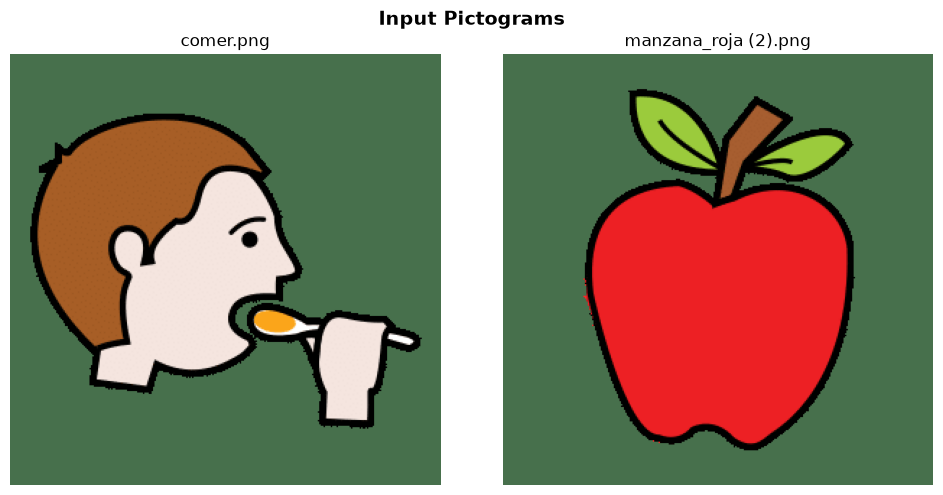

In [3]:
# ============================================================
# Cell 5: Sensory Profile Definition & Image Upload
# ============================================================

# ---- Sensory Profile ----
sensory_profile = {
    "color_fondo_hex": "#FFFFFF",          # Background color
    "nivel_contraste": "alto",              # alto / medio / bajo
    "color_prohibido": ["#FF0000"],         # Forbidden colors (e.g., red)
    "actividad": "comer",                   # Activity name
    "contraste_minimo": 4.5,                # Minimum WCAG contrast ratio
    "k_colores_min": 3,                     # Minimum palette colors
    "k_colores_max": 4                      # Maximum palette colors
}

print("Sensory Profile:")
print(json.dumps(sensory_profile, indent=2))

# ---- Helper: Hex to RGB ----
def hex_to_rgb(hex_color):
    """Convert hex color string to RGB tuple."""
    hex_color = hex_color.lstrip('#')
    return tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))

def rgb_to_hex(rgb):
    """Convert RGB tuple to hex string."""
    return '#{:02x}{:02x}{:02x}'.format(int(rgb[0]), int(rgb[1]), int(rgb[2]))

BG_COLOR = hex_to_rgb(sensory_profile["color_fondo_hex"])
FORBIDDEN_COLORS = [hex_to_rgb(c) for c in sensory_profile["color_prohibido"]]

# ============================================================
# Image Upload - Local execution in VS Code
# ============================================================
# Carpeta donde guardaremos las imágenes de prueba
INPUT_DIR = Path("input")

# Mostrar desde dónde está ejecutándose el notebook
print("Directorio actual:", Path.cwd())
print("Carpetas de imágenes:", INPUT_DIR.resolve())

# Crear la carpeta si todavía no existe
INPUT_DIR.mkdir(parents=True, exist_ok=True)

# Buscar imágenes PNG, JPG, JPEG y WEBP
image_extensions = ["*.png", "*.jpg", "*.jpeg", "*.webp"]
image_paths = []
for extension in image_extensions:
    image_paths.extend(INPUT_DIR.glob(extension))

# Preparar diccionario de imágenes
input_images = {}
for image_path in image_paths:
    try:
        img = Image.open(image_path).convert("RGB")
        input_images[image_path.name] = img
        print(f"✓ Imagen cargada: {image_path.name} | Tamaño: {img.size}")
    except Exception as e:
        print(f"⚠ No se pudo cargar {image_path.name}: {e}")

# Verificar si se encontraron imágenes
if not input_images:
    raise ValueError(
        f"No se encontraron imágenes en: {INPUT_DIR.resolve()}\n"
        "Coloca una imagen PNG, JPG o JPEG dentro de la carpeta 'input'."
    )

# Mostrar imágenes cargadas
fig, axes = plt.subplots(1, len(input_images), figsize=(5 * len(input_images), 5))
if len(input_images) == 1:
    axes = [axes]

for ax, (name, img) in zip(axes, input_images.items()):
    ax.imshow(img)
    ax.set_title(name, fontsize=12)
    ax.axis("off")

plt.suptitle("Input Pictograms", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

comer.png: 9 interior regions detected
manzana_roja (2).png: 6 interior regions detected


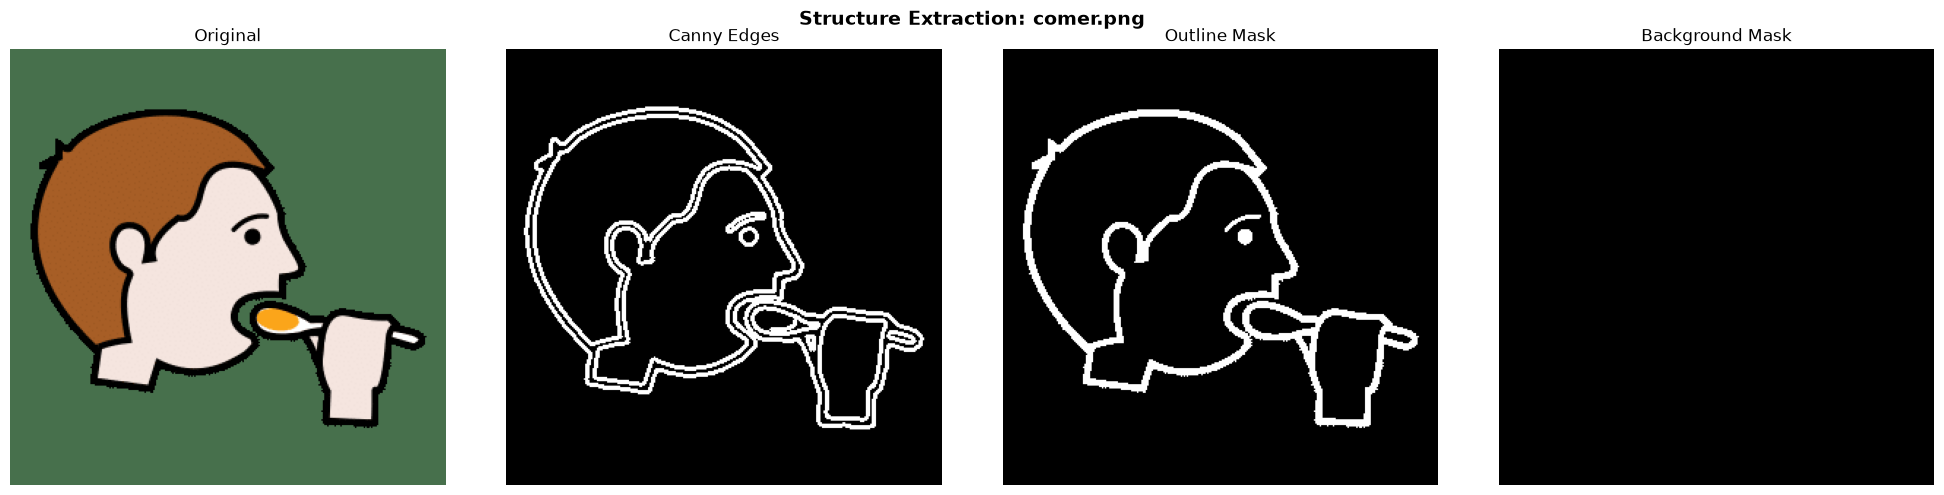

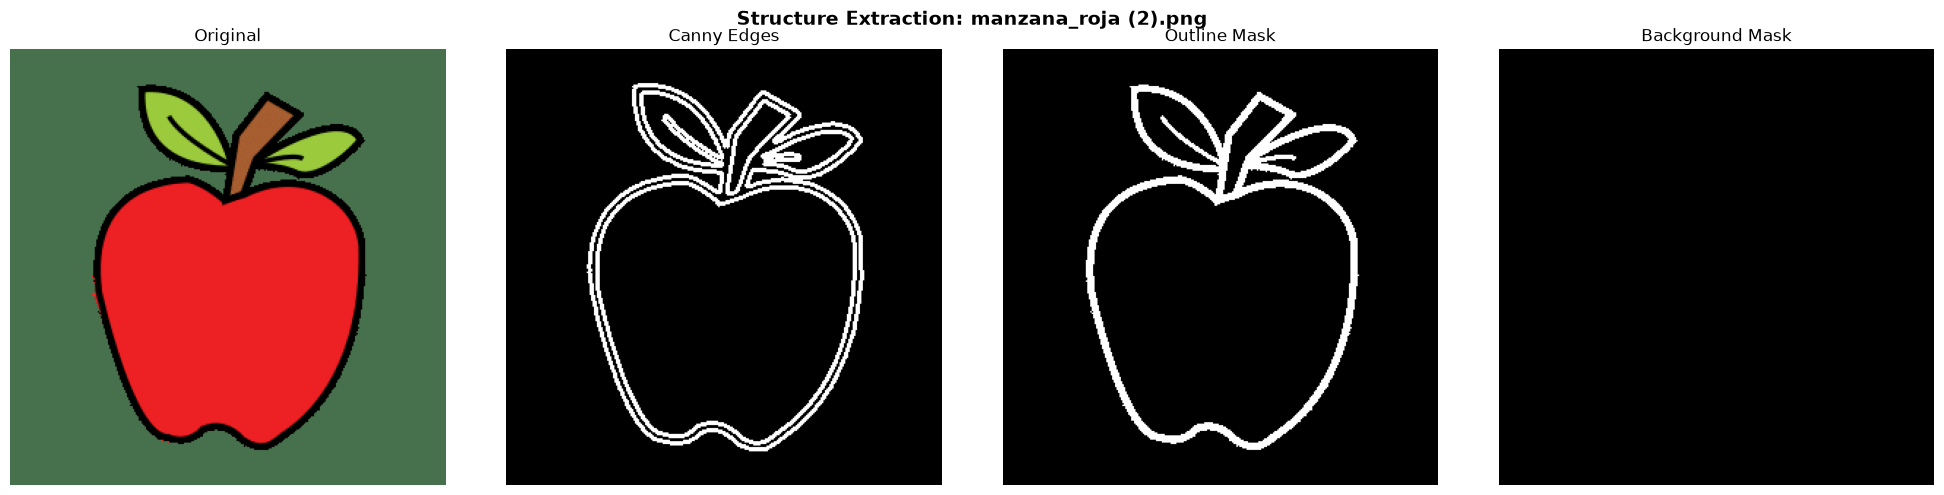

In [4]:
# ============================================================
# Cell 7: Structure Extraction — Canny Edges + Masks
# [FIX #4] Flood fill from ALL edge pixels, not just (0,0)
# ============================================================

def extract_structure(pil_image, canny_low=100, canny_high=200):
    """
    Extract structural information from a pictogram:
    - Canny edge map (for ControlNet conditioning)
    - Outline mask (binary mask of black outlines)
    - Background mask (flood-filled from ALL edges)
    - Connected components of fill regions
    """
    img_np = np.array(pil_image)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)

    # --- Canny Edge Detection ---
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    canny = cv2.Canny(blurred, canny_low, canny_high)

    # Dilate edges to strengthen conditioning signal
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    canny_dilated = cv2.dilate(canny, kernel, iterations=1)

    # Convert to 3-channel for ControlNet
    canny_3ch = np.stack([canny_dilated] * 3, axis=-1)
    canny_pil = Image.fromarray(canny_3ch)

    # --- Outline Mask (dark pixels in original) ---
    outline_mask = (gray < 80).astype(np.uint8) * 255

    # --- Background Mask (flood fill from ALL image edges) ---
    h, w = gray.shape
    light_pixels = (gray > 200).astype(np.uint8) * 255
    bg_flood = light_pixels.copy()

    # Flood fill from every light pixel on the image border
    for x in range(w):
        if bg_flood[0, x] > 0 and bg_flood[0, x] != 128:
            cv2.floodFill(bg_flood, np.zeros((h+2, w+2), np.uint8), (x, 0), 128)
        if bg_flood[h-1, x] > 0 and bg_flood[h-1, x] != 128:
            cv2.floodFill(bg_flood, np.zeros((h+2, w+2), np.uint8), (x, h-1), 128)
    for y in range(h):
        if bg_flood[y, 0] > 0 and bg_flood[y, 0] != 128:
            cv2.floodFill(bg_flood, np.zeros((h+2, w+2), np.uint8), (0, y), 128)
        if bg_flood[y, w-1] > 0 and bg_flood[y, w-1] != 128:
            cv2.floodFill(bg_flood, np.zeros((h+2, w+2), np.uint8), (w-1, y), 128)

    bg_mask = (bg_flood == 128).astype(np.uint8) * 255

    # --- Connected Components of Interior Regions ---
    interior = cv2.bitwise_not(outline_mask | bg_mask)
    # Clean small noise
    interior = cv2.morphologyEx(interior, cv2.MORPH_OPEN, kernel, iterations=1)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        interior, connectivity=8
    )

    return {
        'canny_pil': canny_pil,
        'canny_raw': canny_dilated,
        'outline_mask': outline_mask,
        'bg_mask': bg_mask,
        'interior_labels': labels,
        'interior_stats': stats,
        'interior_centroids': centroids,
        'num_regions': num_labels - 1,  # exclude background label 0
        'gray': gray
    }

# Process all input images
structures = {}
for name, img in input_images.items():
    structures[name] = extract_structure(img)
    s = structures[name]
    print(f"{name}: {s['num_regions']} interior regions detected")

# Visualize
for name, img in input_images.items():
    s = structures[name]
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(img)
    axes[0].set_title('Original', fontsize=12)
    axes[1].imshow(s['canny_raw'], cmap='gray')
    axes[1].set_title('Canny Edges', fontsize=12)
    axes[2].imshow(s['outline_mask'], cmap='gray')
    axes[2].set_title('Outline Mask', fontsize=12)
    axes[3].imshow(s['bg_mask'], cmap='gray')
    axes[3].set_title('Background Mask', fontsize=12)
    for ax in axes:
        ax.axis('off')
    plt.suptitle(f'Structure Extraction: {name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Cell 9: Load ControlNet Pipeline
# ============================================================

print("Loading ControlNet model...")
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=torch.float16
)

print("Loading Stable Diffusion v1.5 pipeline...")
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None  # AAC symbols are safe content
)

# Optimized scheduler: fewer steps, same quality for flat illustrations
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

# Memory optimization for T4
pipe.enable_model_cpu_offload()
try:
    pipe.enable_xformers_memory_efficient_attention()
    print("✓ xformers memory-efficient attention enabled")
except Exception:
    pipe.enable_attention_slicing()
    print("⚠ xformers not available, using attention slicing fallback")

print("✓ Pipeline ready")

Loading ControlNet model...


Loading Stable Diffusion v1.5 pipeline...


Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

## 3.5.4. Generación mediante Stable Diffusion y ControlNet

En esta sección, se explica cómo se utiliza la arquitectura de Stable Diffusion, aumentada con ControlNet, para generar pictogramas a partir de un `prompt` textual y una imagen Canny extraída del pictograma original. El flujo es el siguiente:

**`Prompt` + Imagen Canny + Stable Diffusion + ControlNet → Imagen Generada**

Aquí, se profundiza en los componentes clave de este proceso y su implementación:

### **1. Prompt Engineering**

La función `build_prompts` se encarga de crear un `prompt` positivo y uno negativo detallados. Estos prompts son cruciales para guiar la generación de la imagen:

*   **Prompt positivo**: Describe las características deseadas, como el estilo (AAC, ARASAAC), tipo de ilustración (vectorial, 2D, colores planos), el sujeto de la actividad (ej. "una persona comiendo con una cuchara de un tazón"), el color de fondo, el contraste perceptual y las características del dibujo (contornos finos, minimalista, apto para niños).
*   **Prompt negativo**: Enumera las características que se deben evitar, como bajo contraste, sombras, degradados, texturas, efectos 3D, colores oscuros o prohibidos, y elementos que distraigan.

### **2. ControlNet y Stable Diffusion Pipeline**

La biblioteca `diffusers` de Hugging Face se utiliza para cargar y ejecutar el modelo. La celda `P0-6KcDtF9Ss` carga dos modelos principales:

*   **ControlNet (`lllyasviel/sd-controlnet-canny`)**: Este es un modelo que "controla" la Stable Diffusion, permitiéndole generar imágenes que adhieren a una estructura espacial específica. En este caso, se le proporciona una imagen de bordes Canny del pictograma original. ControlNet se entrena para tomar esta "condición" extra y guiar el proceso de difusión, asegurando que la imagen generada respete los contornos del original.

*   **Stable Diffusion (`stable-diffusion-v1-5/stable-diffusion-v1-5`)**: Este es el modelo base de generación de texto a imagen. Dentro de este modelo, operan varios componentes clave:

    *   **Text Encoder (Codificador de Texto)**: Toma el `prompt` (positivo y negativo) y lo convierte en representaciones numéricas llamadas "embeddings". Estos embeddings capturan el significado semántico del texto y son utilizados por el UNet para entender qué generar.

    *   **UNet (Generador de Ruido)**: Es el corazón del proceso de difusión. Recibe el `latent` ruidoso (una representación comprimida de la imagen) y los embeddings del texto. El UNet elimina iterativamente el ruido del `latent`, guiado por las instrucciones del `prompt` y, en nuestro caso, por la condición adicional de ControlNet. Su objetivo es transformar un `latent` aleatorio en un `latent` coherente con el `prompt` y la imagen Canny.

    *   **VAE (Autoencoder Variacional)**: El VAE tiene dos funciones principales:
        *   **Codificador (Encoder)**: Toma una imagen en el espacio de píxeles (ej. la imagen Canny) y la comprime a un espacio `latent` de menor dimensión, donde el UNet opera de manera más eficiente.
        *   **Decodificador (Decoder)**: Una vez que el UNet ha refinado el `latent` ruidoso en un `latent` de imagen de alta calidad, el decodificador del VAE toma este `latent` y lo convierte de nuevo a una imagen en el espacio de píxeles (RGB), que es la salida final visible.

### **3. Proceso de Generación (`generate_with_controlnet`)**

La función `generate_with_controlnet` orquesta estos componentes:

1.  **Entrada**: Recibe la imagen Canny (`canny_pil`), el `prompt` positivo y negativo, y un `seed` para la reproducibilidad.
2.  **Redimensionamiento**: La imagen Canny se redimensiona a 512x512 píxeles, que es el tamaño de entrada estándar para muchos modelos de Stable Diffusion.
3.  **Generador Aleatorio**: Un `torch.Generator` con un `seed` fijo asegura que, para un mismo `seed`, la generación sea idéntica cada vez.
4.  **Ejecución del Pipeline**: El método `pipe()` del `StableDiffusionControlNetPipeline` es invocado con los `prompts`, la imagen Canny (`image`), el número de pasos de inferencia (`num_inference_steps`), y la escala de guía (`guidance_scale`), entre otros parámetros. ControlNet se encarga de inyectar la información de los bordes en cada paso de la difusión del UNet.
5.  **Salida**: El pipeline devuelve una imagen PIL generada, que es el pictograma adaptado a la estructura original y el estilo del `prompt`.

## 3.5.5. Generación de múltiples candidatos y selección mediante SSIM

El sistema no se limita a generar una única imagen y aceptarla. Para garantizar la robustez y calidad del resultado, se implementa un proceso de generación multi-candidato seguido de una selección basada en la similitud estructural.

### **Proceso de Generación y Selección:**

1.  **Generación con múltiples `seed`s:** La función `generate_best_of_n` (ubicada en la celda `o766iPd8F9Sy`) toma una imagen Canny original y, en lugar de usar un único valor `seed` para la generación de Stable Diffusion, itera a través de una lista predefinida de `seed`s (por ejemplo, `[42, 123, 7, 2024, 99]`).
    *   Por cada `seed`, se llama a `generate_with_controlnet` para producir una imagen candidata.
    *   Esto resulta en múltiples imágenes generadas, cada una ligeramente diferente debido al `seed` aleatorio inicial, pero todas condicionadas por el mismo `prompt` y la misma imagen Canny.

2.  **Comparación estructural mediante SSIM:** Para seleccionar la mejor imagen de entre los candidatos, se utiliza el **Índice de Similitud Estructural (SSIM)**.
    *   Cada imagen candidata generada se convierte a escala de grises y se le aplica la detección de bordes Canny para obtener un mapa de bordes. Lo mismo se hace con la imagen original.
    *   El SSIM se calcula entre el mapa de bordes Canny de la imagen *original* y el mapa de bordes Canny de cada imagen *candidata*.
    *   El SSIM es una métrica que evalúa la similitud entre dos imágenes basándose en tres componentes: luminancia, contraste y estructura. Un valor de SSIM más alto indica una mayor similitud estructural.

3.  **Selección del mejor resultado:** La imagen candidata que obtiene el valor SSIM más alto con respecto a la imagen Canny original es seleccionada como el mejor resultado. Este método ayuda a asegurar que la imagen final mantenga la integridad estructural del pictograma original, incluso cuando Stable Diffusion introduce variaciones.

Esta característica técnica es crucial porque mitiga las posibles variaciones no deseadas en la salida de los modelos generativos, asegurando una mayor fidelidad a la estructura del pictograma original y, por ende, una mayor consistencia y utilidad clínica.

Token indices sequence length is longer than the specified maximum sequence length for this model (107 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['bold distinct colors , thin dark outlines , minimalist , child - friendly , clear semantic separation between objects , clip art , icon , pictograph , white background']



--- Generating: beber.png ---
Positive: simple flat-color AAC pictogram, ARASAAC style, vector illustration of a person drinking water from a cup, solid color f...
Negative: red, low contrast, shadows, gradients, textures, shading, realistic rendering, 3D, lighting effects,...


  0%|          | 0/20 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['bold distinct colors , thin dark outlines , minimalist , child - friendly , clear semantic separation between objects , clip art , icon , pictograph , white background']


    Seed 42: SSIM = 0.782


...

  0%|          | 0/20 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['tual contrast , bold distinct colors , thin dark outlines , minimalist , child - friendly , clear semantic separation between objects , clip art , icon , pictograph , white background']


    Seed 2024: SSIM = 0.825


  0%|          | 0/20 [00:00<?, ?it/s]

    Seed 99: SSIM = 0.868
    → Selected seed 99 (SSIM=0.868)
✓ Generated comer.png (best SSIM: 0.868)


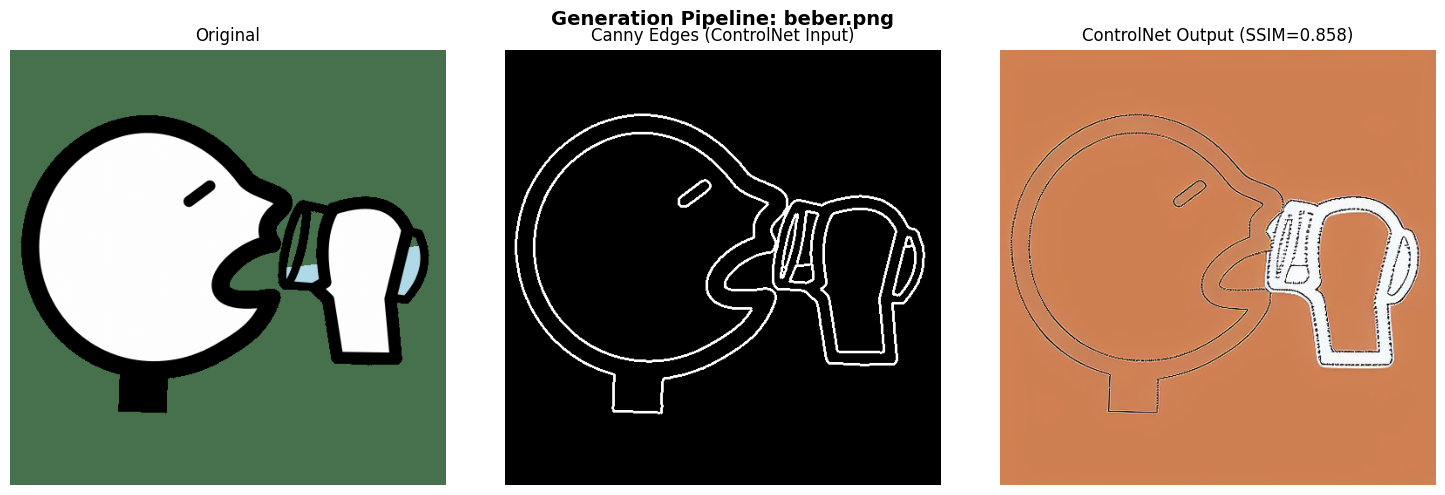

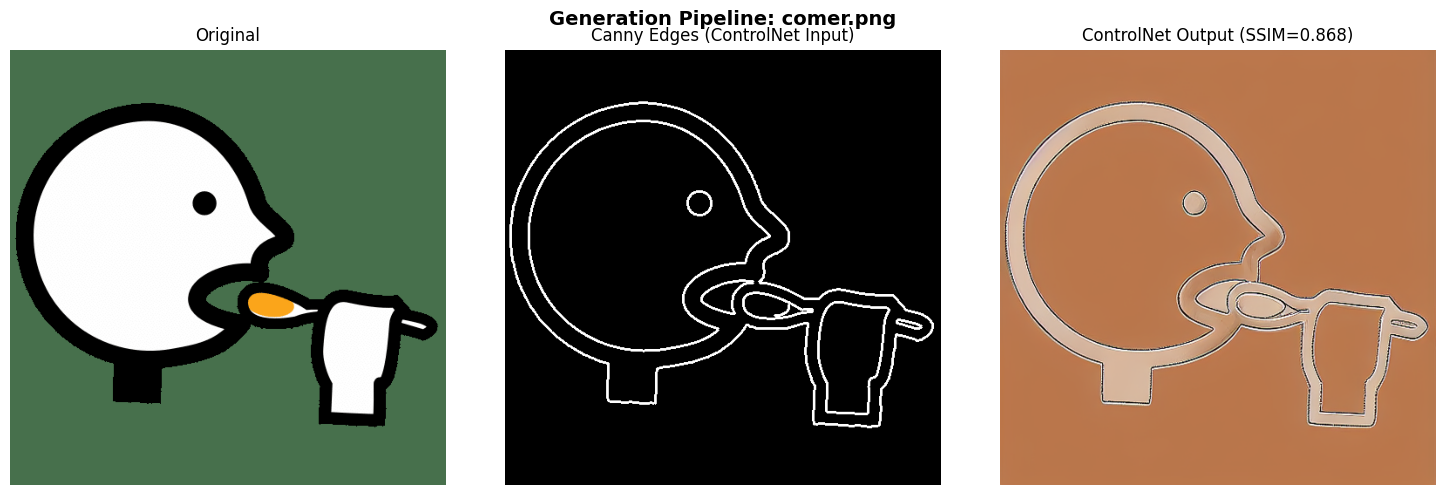

In [ ]:
# ============================================================
# Cell 10: Build Prompts & Generate with ControlNet
# [FIX #1] conditioning_scale 1.3 -> 1.7
# [FIX #2] Stronger prompt engineering
# [FIX #3] Multi-seed generation with SSIM quality check
# ============================================================

# Activity-to-description mapping
ACTIVITY_DESCRIPTIONS = {
    "comer": "a person eating food with a spoon from a bowl",
    "beber": "a person drinking water from a cup",
    "dormir": "a person sleeping in a bed",
    "jugar": "a child playing with a toy",
    "lavar": "a person washing hands with water",
}

def build_prompts(image_name, profile):
    """Build strict AAC-style positive and negative prompts."""
    activity = Path(image_name).stem.lower()
    # Strip trailing numbers/parentheses from filenames like 'comer (1)'
    for suffix in [' (1)', ' (2)', ' (3)', '_1', '_2']:
        activity = activity.replace(suffix, '')
    activity = activity.strip()

    activity_desc = ACTIVITY_DESCRIPTIONS.get(
        activity,
        f"a person performing the action of {activity}"
    )

    bg_hex = profile['color_fondo_hex']

    contrast_modifier = {
        "alto": "high perceptual contrast, bold distinct colors",
        "medio": "medium perceptual contrast, clear distinct colors",
        "bajo": "soft perceptual contrast, gentle distinct colors"
    }.get(profile['nivel_contraste'], "high perceptual contrast")

    # [FIX #2] Stronger positive prompt — lead with style anchors
    positive = (
        f"simple flat-color AAC pictogram, ARASAAC style, "
        f"vector illustration of {activity_desc}, "
        f"solid color fills, cel-shaded, 2D, "
        f"peach skin tone face, distinct colored objects, "
        f"flat colors only, no gradients, no shadows, no textures, no lighting, "
        f"uniform {bg_hex} background, "
        f"{contrast_modifier}, "
        f"thin dark outlines, minimalist, child-friendly, "
        f"clear semantic separation between objects, "
        f"clip art, icon, pictograph, white background"
    )

    # Build forbidden color names
    forbidden_names = []
    for fc in profile.get('color_prohibido', []):
        rgb = hex_to_rgb(fc)
        if rgb[0] > 200 and rgb[1] < 80 and rgb[2] < 80:
            forbidden_names.append("red")
        elif rgb[0] < 80 and rgb[1] > 200 and rgb[2] < 80:
            forbidden_names.append("green")
        elif rgb[0] < 80 and rgb[1] < 80 and rgb[2] > 200:
            forbidden_names.append("blue")
        else:
            forbidden_names.append(f"color {fc}")

    forbidden_str = ", ".join(forbidden_names) + ", " if forbidden_names else ""

    # [FIX #2] Stronger negative prompt — block dark fills, metallic, 3D artifacts
    negative = (
        f"{forbidden_str}"
        f"low contrast, shadows, gradients, textures, shading, "
        f"realistic rendering, 3D, lighting effects, depth, perspective, "
        f"dark colors, dark skin, dark face, gray face, gray fill, muddy colors, black fill, "
        f"clutter, soft edges, blurry, noise, grain, "
        f"photorealistic, photograph, HDR, ray tracing, "
        f"helmet, armor, metallic, glossy, reflection, "
        f"complex background, watermark, text, multiple scenes, busy"
    )

    return positive, negative


def generate_with_controlnet(canny_pil, positive_prompt, negative_prompt,
                              seed=42, num_steps=20, guidance=7.5,
                              conditioning_scale=1.7):  # [FIX #1] 1.3 -> 1.7
    """Generate an image using ControlNet with Canny conditioning."""
    canny_resized = canny_pil.resize((512, 512), Image.LANCZOS)

    generator = torch.Generator(device='cpu').manual_seed(seed)

    output = pipe(
        prompt=positive_prompt,
        negative_prompt=negative_prompt,
        image=canny_resized,
        num_inference_steps=num_steps,
        guidance_scale=guidance,
        controlnet_conditioning_scale=conditioning_scale,
        generator=generator,
    )

    return output.images[0]


# [FIX #3] Multi-seed generation: generate N candidates, pick best by SSIM
def generate_best_of_n(canny_pil, original_pil, positive_prompt, negative_prompt,
                       seeds=None, num_steps=20, guidance=7.5,
                       conditioning_scale=1.7):
    """
    Generate multiple candidates with different seeds.
    Select the one with highest structural similarity (SSIM) to the original.
    This prevents single-seed failures from ruining the output.
    """
    if seeds is None:
        seeds = [42, 123, 7, 2024, 99]

    orig_gray = cv2.cvtColor(np.array(original_pil.resize((512, 512), Image.LANCZOS)),
                             cv2.COLOR_RGB2GRAY)
    orig_canny = cv2.Canny(orig_gray, 100, 200)

    best_img = None
    best_score = -1
    best_seed = seeds[0]

    for seed in seeds:
        candidate = generate_with_controlnet(
            canny_pil, positive_prompt, negative_prompt,
            seed=seed, num_steps=num_steps, guidance=guidance,
            conditioning_scale=conditioning_scale
        )
        cand_gray = cv2.cvtColor(np.array(candidate), cv2.COLOR_RGB2GRAY)
        cand_canny = cv2.Canny(cand_gray, 100, 200)
        score = ssim(orig_canny, cand_canny)
        print(f"    Seed {seed}: SSIM = {score:.3f}")

        if score > best_score:
            best_score = score
            best_img = candidate
            best_seed = seed

    print(f"    → Selected seed {best_seed} (SSIM={best_score:.3f})")
    return best_img, best_score


# Generate for all images
generated_images = {}
generation_scores = {}  # Store SSIM scores for fallback logic

for name, img in input_images.items():
    s = structures[name]
    pos, neg = build_prompts(name, sensory_profile)

    print(f"\n--- Generating: {name} ---")
    print(f"Positive: {pos[:120]}...")
    print(f"Negative: {neg[:100]}...")

    # [FIX #3] Use multi-seed generation
    gen_img, gen_score = generate_best_of_n(
        s['canny_pil'], img, pos, neg,
        conditioning_scale=1.7
    )

    # Resize back to original size
    gen_img = gen_img.resize(img.size, Image.LANCZOS)
    generated_images[name] = gen_img
    generation_scores[name] = gen_score
    print(f"✓ Generated {name} (best SSIM: {gen_score:.3f})")

# Display: Original | Canny | Generated
for name in input_images:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(input_images[name])
    axes[0].set_title('Original', fontsize=12)
    axes[1].imshow(structures[name]['canny_raw'], cmap='gray')
    axes[1].set_title('Canny Edges (ControlNet Input)', fontsize=12)
    axes[2].imshow(generated_images[name])
    axes[2].set_title(f'ControlNet Output (SSIM={generation_scores[name]:.3f})', fontsize=12)
    for ax in axes:
        ax.axis('off')
    plt.suptitle(f'Generation Pipeline: {name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Cell 12: Step 4.1 — Enforce Uniform Background
# [FIX #8] Flood fill from ALL edge pixels
# ============================================================

def enforce_background(image_np, bg_mask, bg_color_rgb):
    """
    Replace all background pixels with the exact profile background color.
    Uses aggressive flood fill from all image border pixels.
    """
    result = image_np.copy()

    # Detect near-background pixels in the generated image
    gray_gen = cv2.cvtColor(result, cv2.COLOR_RGB2GRAY)
    light_mask = (gray_gen > 220).astype(np.uint8) * 255

    # Combine: original background mask OR very light areas
    combined_bg = cv2.bitwise_or(bg_mask, light_mask)

    # [FIX #8] Flood fill from ALL border pixels (not just corners)
    h, w = combined_bg.shape
    flood = combined_bg.copy()
    for x in range(w):
        if flood[0, x] > 0 and flood[0, x] != 128:
            cv2.floodFill(flood, np.zeros((h+2, w+2), np.uint8), (x, 0), 128)
        if flood[h-1, x] > 0 and flood[h-1, x] != 128:
            cv2.floodFill(flood, np.zeros((h+2, w+2), np.uint8), (x, h-1), 128)
    for y in range(h):
        if flood[y, 0] > 0 and flood[y, 0] != 128:
            cv2.floodFill(flood, np.zeros((h+2, w+2), np.uint8), (0, y), 128)
        if flood[y, w-1] > 0 and flood[y, w-1] != 128:
            cv2.floodFill(flood, np.zeros((h+2, w+2), np.uint8), (w-1, y), 128)

    final_bg = (flood == 128).astype(np.uint8) * 255

    # Apply exact background color
    result[final_bg > 0] = bg_color_rgb

    return result, final_bg

print("✓ Step 4.1: enforce_background() defined")

✓ Step 4.1: enforce_background() defined


In [ ]:
# ============================================================
# Cell 14: Step 4.2 — Remove Shadows and Gradients
# [FIX #7] Threshold lowered from 15 to 10 for stricter flattening
# ============================================================

def remove_shadows_gradients(image_np, outline_mask, bg_mask_final):
    """
    Force flat color regions by detecting and eliminating gradients.
    For each interior region, if the color variance is high (gradient/shadow),
    replace all pixels with the median color of that region.
    """
    result = image_np.copy()

    # Interior = not outline, not background
    interior = cv2.bitwise_not(cv2.bitwise_or(outline_mask, bg_mask_final))

    # Find connected regions in interior
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    interior_clean = cv2.morphologyEx(interior, cv2.MORPH_OPEN, kernel)
    num_labels, labels = cv2.connectedComponents(interior_clean, connectivity=8)

    for label_id in range(1, num_labels):
        mask = (labels == label_id)
        if mask.sum() < 30:  # skip tiny regions (noise)
            continue

        region_pixels = result[mask]

        # [FIX #7] Stricter threshold: 10 instead of 15
        std_per_channel = region_pixels.std(axis=0)
        if std_per_channel.max() > 10:
            # Replace with median color (more robust than mean)
            median_color = np.median(region_pixels, axis=0).astype(np.uint8)
            result[mask] = median_color

    # Apply bilateral filter to smooth remaining anti-aliasing at edges
    result = cv2.bilateralFilter(result, d=5, sigmaColor=50, sigmaSpace=50)

    return result

print("✓ Step 4.2: remove_shadows_gradients() defined")

✓ Step 4.2: remove_shadows_gradients() defined


In [ ]:
# ============================================================
# Cell 16: Step 4.3 — Edge Refinement
# ============================================================

def refine_edges(image_np, outline_mask, edge_color=(60, 60, 60), thickness=3):
    """
    Re-apply clean, consistent edges from the original outline mask.
    Uses dark gray (not pure black) to provide structure without being dominant.
    """
    result = image_np.copy()

    # Dilate outline mask to target thickness
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (thickness, thickness))
    thick_outlines = cv2.dilate(outline_mask, kernel, iterations=1)

    # Close small gaps in outlines
    thick_outlines = cv2.morphologyEx(
        thick_outlines, cv2.MORPH_CLOSE, kernel, iterations=1
    )

    # Apply edge color
    result[thick_outlines > 0] = edge_color

    return result, thick_outlines

print("✓ Step 4.3: refine_edges() defined")

✓ Step 4.3: refine_edges() defined


In [ ]:
# ============================================================
# Cell 18: Step 4.4 — Adaptive Per-Region K-Means Color Reduction
# ============================================================

def adaptive_color_reduction(image_np, outline_mask, bg_mask_final, profile):
    """
    CRITICAL: Per-region color quantization, NOT global K-Means.

    1. Segment into connected components (each semantic region)
    2. Apply K-Means independently per region
    3. Build global palette, merge if exceeding k_colores_max

    This preserves semantic separability — objects maintain distinct colors.
    """
    result = image_np.copy()
    k_min = profile['k_colores_min']
    k_max = profile['k_colores_max']

    # Find interior regions
    interior = cv2.bitwise_not(cv2.bitwise_or(outline_mask, bg_mask_final))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    interior = cv2.morphologyEx(interior, cv2.MORPH_OPEN, kernel)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        interior, connectivity=8
    )

    # Per-region quantization
    region_colors = {}  # label_id -> dominant RGB color
    region_areas = {}   # label_id -> pixel count

    for label_id in range(1, num_labels):
        mask = (labels == label_id)
        area = mask.sum()
        if area < 50:  # skip noise
            continue

        region_pixels = result[mask].astype(np.float32)
        std_per_ch = region_pixels.std(axis=0)

        if area < 100 or std_per_ch.max() < 10:
            # Already flat — use mean color
            dominant = region_pixels.mean(axis=0).astype(np.uint8)
        else:
            # Apply K-Means within this region
            n_clusters = min(3, max(1, int(std_per_ch.max() / 20)))
            kmeans = MiniBatchKMeans(
                n_clusters=n_clusters, random_state=42, batch_size=256
            )
            kmeans.fit(region_pixels)

            # Find the largest cluster (dominant color)
            cluster_sizes = np.bincount(kmeans.labels_)
            dominant_idx = cluster_sizes.argmax()
            dominant = kmeans.cluster_centers_[dominant_idx].astype(np.uint8)

        # Apply dominant color to entire region
        result[mask] = dominant
        region_colors[label_id] = tuple(dominant.tolist())
        region_areas[label_id] = area

    # --- Global Palette Merge (if exceeding k_max) ---
    unique_colors = list(set(region_colors.values()))

    if len(unique_colors) > k_max:
        while len(unique_colors) > k_max:
            # Convert to LAB for perceptually uniform distance
            lab_colors = []
            for c in unique_colors:
                pixel = np.uint8([[list(c)]])
                lab = cv2.cvtColor(pixel, cv2.COLOR_RGB2LAB)[0][0].astype(float)
                lab_colors.append(lab)

            # Find the two closest colors
            min_dist = float('inf')
            merge_pair = (0, 1)
            for i in range(len(lab_colors)):
                for j in range(i+1, len(lab_colors)):
                    dist = np.linalg.norm(lab_colors[i] - lab_colors[j])
                    if dist < min_dist:
                        min_dist = dist
                        merge_pair = (i, j)

            # Merge: weighted average by total area
            c1, c2 = unique_colors[merge_pair[0]], unique_colors[merge_pair[1]]
            area1 = sum(a for lid, a in region_areas.items()
                       if region_colors.get(lid) == c1)
            area2 = sum(a for lid, a in region_areas.items()
                       if region_colors.get(lid) == c2)
            total = area1 + area2
            if total == 0:
                total = 1
            merged = tuple(
                int((c1[ch] * area1 + c2[ch] * area2) / total)
                for ch in range(3)
            )

            for lid in region_colors:
                if region_colors[lid] in (c1, c2):
                    region_colors[lid] = merged
            unique_colors = list(set(region_colors.values()))

        # Re-apply merged palette
        for label_id, color in region_colors.items():
            mask = (labels == label_id)
            if mask.sum() >= 50:
                result[mask] = color

    # Build final palette info
    final_palette = list(set(region_colors.values()))
    print(f"  Palette: {len(final_palette)} colors")
    for i, c in enumerate(final_palette):
        print(f"    Color {i+1}: RGB{c} = {rgb_to_hex(c)}")

    return result, region_colors, labels, final_palette

print("✓ Step 4.4: adaptive_color_reduction() defined")

✓ Step 4.4: adaptive_color_reduction() defined


In [ ]:
# ============================================================
# Cell 20: Step 4.5 — Semantic Color Assignment
# [FIX #5] Uses ORIGINAL image colors for classification,
#          not the (potentially wrong) generated image colors
# ============================================================

# Semantic color rules — each object type gets a distinct color role
SEMANTIC_RULES = {
    "skin": {
        "hue_range": (10, 50),       # warm tones
        "sat_range": (0.1, 0.6),
        "default_rgb": (255, 218, 185),  # peach
    },
    "food": {
        "hue_range": (15, 50),       # orange-yellow
        "sat_range": (0.4, 1.0),
        "default_rgb": (255, 165, 0),    # orange
    },
    "liquid": {
        "hue_range": (180, 220),     # blue-cyan
        "sat_range": (0.2, 0.8),
        "default_rgb": (135, 206, 235),  # sky blue
    },
    "object": {
        "hue_range": None,           # catch-all for neutral/gray
        "sat_range": (0.0, 0.15),
        "default_rgb": (192, 192, 192),  # silver
    },
}

def rgb_to_hsv_tuple(rgb):
    """Convert RGB (0-255) to HSV with H in degrees, S and V in 0-1."""
    r, g, b = rgb[0]/255.0, rgb[1]/255.0, rgb[2]/255.0
    h, s, v = colorsys.rgb_to_hsv(r, g, b)
    return h * 360, s, v

def is_color_forbidden(rgb, forbidden_list, tolerance=60):
    """Check if a color is too close to any forbidden color."""
    for fc in forbidden_list:
        dist = np.sqrt(sum((a - b) ** 2 for a, b in zip(rgb, fc)))
        if dist < tolerance:
            return True
    return False

def classify_region_semantic(rgb):
    """Classify a region color into a semantic category."""
    h, s, v = rgb_to_hsv_tuple(rgb)

    # Very light / near-white regions -> likely skin/body (unfilled in original)
    if v > 0.9 and s < 0.1:
        return "skin"  # Light unfilled regions in ARASAAC are typically body/face

    # Check saturation first — low saturation = object/neutral
    if s < 0.15 and v < 0.9:
        return "object"

    # Check hue ranges
    if 180 <= h <= 220 and s >= 0.2:
        return "liquid"
    if 15 <= h <= 50 and s >= 0.4:
        return "food"
    if 10 <= h <= 50 and s < 0.4:
        return "skin"

    return "object"  # default


def assign_semantic_colors(image_np, region_colors, labels, profile, original_np=None):
    """
    Rule-based semantic color assignment.
    [FIX #5] Uses ORIGINAL image colors for classification — the generated
    image may have completely wrong colors, but the original ARASAAC
    pictogram has correct semantic colors (orange food, blue liquid, etc.).
    """
    result = image_np.copy()
    forbidden = FORBIDDEN_COLORS
    ref_image = original_np if original_np is not None else image_np

    region_semantics = {}
    assigned_colors = {}
    used_categories = set()

    # Sort regions by area (largest first — likely the face/body)
    sorted_regions = sorted(
        region_colors.items(),
        key=lambda x: (labels == x[0]).sum(),
        reverse=True
    )

    for label_id, current_color in sorted_regions:
        mask = (labels == label_id)
        if mask.sum() < 50:
            continue

        # [FIX #5] Sample from ORIGINAL image for classification
        if original_np is not None:
            orig_pixels = ref_image[mask]
            if len(orig_pixels) > 0:
                ref_color = tuple(np.median(orig_pixels, axis=0).astype(int).tolist())
            else:
                ref_color = current_color
        else:
            ref_color = current_color

        category = classify_region_semantic(ref_color)
        region_semantics[label_id] = category

        # Get target color for this category
        rule = SEMANTIC_RULES[category]
        target_color = rule['default_rgb']

        # Check if forbidden
        if is_color_forbidden(target_color, forbidden):
            h, s, v = rgb_to_hsv_tuple(target_color)
            h = (h + 30) % 360
            r, g, b = colorsys.hsv_to_rgb(h/360, s, v)
            target_color = (int(r*255), int(g*255), int(b*255))

        # Ensure different categories get distinct colors
        if category in used_categories:
            h, s, v = rgb_to_hsv_tuple(target_color)
            h = (h + 15 * len([c for c in used_categories if c == category])) % 360
            r, g, b = colorsys.hsv_to_rgb(h/360, min(1, s * 1.1), v)
            target_color = (int(r*255), int(g*255), int(b*255))

        used_categories.add(category)
        assigned_colors[label_id] = target_color

        # Apply to image
        if mask.sum() >= 50:
            result[mask] = target_color

    # Report
    for lid, sem in region_semantics.items():
        c = assigned_colors.get(lid, (0,0,0))
        print(f"  Region {lid}: {sem} -> RGB{c} ({rgb_to_hex(c)})")

    return result, assigned_colors, region_semantics

print("✓ Step 4.5: assign_semantic_colors() defined")

✓ Step 4.5: assign_semantic_colors() defined


In [ ]:
# ============================================================
# Cell 22: Step 4.6 — WCAG Contrast Validation & Correction
# ============================================================

def relative_luminance(rgb):
    """Compute WCAG 2.0 relative luminance from RGB (0-255)."""
    channels = []
    for c in rgb:
        c_norm = c / 255.0
        if c_norm <= 0.03928:
            channels.append(c_norm / 12.92)
        else:
            channels.append(((c_norm + 0.055) / 1.055) ** 2.4)
    return 0.2126 * channels[0] + 0.7152 * channels[1] + 0.0722 * channels[2]


def contrast_ratio(color1, color2):
    """Compute WCAG contrast ratio between two RGB colors."""
    l1 = relative_luminance(color1)
    l2 = relative_luminance(color2)
    lighter = max(l1, l2)
    darker = min(l1, l2)
    return (lighter + 0.05) / (darker + 0.05)


def adjust_for_contrast(fg_color, bg_color, min_ratio):
    """
    Adjust foreground color to meet minimum contrast ratio against background.
    Preserves hue and saturation, adjusts lightness in HLS space.
    """
    current_ratio = contrast_ratio(fg_color, bg_color)
    if current_ratio >= min_ratio:
        return fg_color, current_ratio

    r, g, b = fg_color[0]/255.0, fg_color[1]/255.0, fg_color[2]/255.0
    h, l, s = colorsys.rgb_to_hls(r, g, b)

    bg_lum = relative_luminance(bg_color)
    direction = -1 if bg_lum > 0.5 else 1

    for step in range(50):
        l = max(0.0, min(1.0, l + direction * 0.02))
        r2, g2, b2 = colorsys.hls_to_rgb(h, l, s)
        new_color = (int(r2*255), int(g2*255), int(b2*255))
        new_ratio = contrast_ratio(new_color, bg_color)
        if new_ratio >= min_ratio:
            return new_color, new_ratio

    r2, g2, b2 = colorsys.hls_to_rgb(h, l, s)
    return (int(r2*255), int(g2*255), int(b2*255)), contrast_ratio(
        (int(r2*255), int(g2*255), int(b2*255)), bg_color
    )


def validate_and_fix_contrast(image_np, assigned_colors, labels, profile):
    """
    Validate all region-to-background and region-to-outline contrast ratios.
    Auto-correct colors that fail the minimum threshold.
    """
    result = image_np.copy()
    min_contrast = profile['contraste_minimo']
    bg_color = BG_COLOR
    outline_color = (60, 60, 60)

    report = []
    corrected_colors = {}

    for label_id, color in assigned_colors.items():
        mask = (labels == label_id)
        if mask.sum() < 50:
            continue

        ratio_bg = contrast_ratio(color, bg_color)
        ratio_outline = contrast_ratio(color, outline_color)

        new_color = color
        adjusted = False

        if ratio_bg < min_contrast:
            new_color, ratio_bg = adjust_for_contrast(new_color, bg_color, min_contrast)
            adjusted = True

        ratio_outline = contrast_ratio(new_color, outline_color)
        if ratio_outline < 3.0:
            new_color, ratio_outline = adjust_for_contrast(
                new_color, outline_color, 3.0
            )
            adjusted = True

        if adjusted:
            result[mask] = new_color

        corrected_colors[label_id] = new_color
        status = "✓" if ratio_bg >= min_contrast else "✗"
        report.append({
            'region': label_id,
            'color': new_color,
            'contrast_vs_bg': round(ratio_bg, 2),
            'contrast_vs_outline': round(ratio_outline, 2),
            'adjusted': adjusted,
            'pass': ratio_bg >= min_contrast
        })

    print(f"  Contrast Validation (minimum ratio: {min_contrast}:1):")
    for r in report:
        status = "PASS" if r['pass'] else "FAIL"
        adj = " (adjusted)" if r['adjusted'] else ""
        print(f"    Region {r['region']}: vs BG={r['contrast_vs_bg']}:1, "
              f"vs outline={r['contrast_vs_outline']}:1 [{status}]{adj}")

    return result, corrected_colors, report

print("✓ Step 4.6: validate_and_fix_contrast() defined")

✓ Step 4.6: validate_and_fix_contrast() defined


In [ ]:
# ============================================================
# Cell 24: Step 4.7 — Semantic Fill + Step 4.8 — Visual Hierarchy
# ============================================================

def ensure_semantic_fill(image_np, labels, corrected_colors, outline_mask, bg_mask):
    """
    Step 4.7: Ensure all main shapes have solid fill (no wireframe results).
    Any interior pixel not assigned a color gets the nearest region's color.
    """
    result = image_np.copy()

    interior = cv2.bitwise_not(cv2.bitwise_or(outline_mask, bg_mask))
    for y in range(result.shape[0]):
        for x in range(result.shape[1]):
            if interior[y, x] > 0 and labels[y, x] == 0:
                best_label = 0
                for dy, dx in [(-1,0),(1,0),(0,-1),(0,1),(-1,-1),(1,1),(-1,1),(1,-1)]:
                    ny, nx = y+dy, x+dx
                    if (0 <= ny < labels.shape[0] and 0 <= nx < labels.shape[1]
                            and labels[ny, nx] > 0):
                        best_label = labels[ny, nx]
                        break
                if best_label > 0 and best_label in corrected_colors:
                    result[y, x] = corrected_colors[best_label]

    return result


def apply_visual_hierarchy(image_np, region_semantics, corrected_colors,
                           labels, profile):
    """
    Step 4.8: Make the action area (food/liquid) the most visually salient region.
    """
    result = image_np.copy()
    action_categories = {'food', 'liquid'}

    for label_id, category in region_semantics.items():
        if category in action_categories:
            color = corrected_colors.get(label_id)
            if color is None:
                continue

            r, g, b = color[0]/255.0, color[1]/255.0, color[2]/255.0
            h, l, s = colorsys.rgb_to_hls(r, g, b)
            s_boosted = min(1.0, s * 1.2)
            if l > 0.5:
                l_adj = max(0.4, l - 0.05)
            else:
                l_adj = min(0.6, l + 0.05)
            r2, g2, b2 = colorsys.hls_to_rgb(h, l_adj, s_boosted)
            boosted_color = (int(r2*255), int(g2*255), int(b2*255))

            if contrast_ratio(boosted_color, BG_COLOR) >= profile['contraste_minimo']:
                mask = (labels == label_id)
                if mask.sum() >= 50:
                    result[mask] = boosted_color
                    corrected_colors[label_id] = boosted_color
                    print(f"  Boosted region {label_id} ({category}): "
                          f"RGB{color} -> RGB{boosted_color}")

    return result

print("✓ Steps 4.7-4.8: ensure_semantic_fill() and apply_visual_hierarchy() defined")

✓ Steps 4.7-4.8: ensure_semantic_fill() and apply_visual_hierarchy() defined


In [ ]:
# ============================================================
# Cell 26: Master Post-Processing Pipeline
# [FIX #6] Fallback to original image if SSIM < 0.5
# [FIX #9] Reorder: edges BEFORE color reduction
# [FIX #5] Pass original_np for semantic classification
# ============================================================

def clinical_postprocess(generated_pil, original_pil, structure, profile,
                         generation_ssim=1.0):
    """
    Master pipeline: chains all post-processing steps.
    Falls back to colorizing the original if ControlNet output is too divergent.
    """
    original_np = np.array(original_pil)
    outline_mask = structure['outline_mask']
    bg_mask = structure['bg_mask']

    # [FIX #6] FALLBACK: If generation was too divergent, use original as base
    if generation_ssim < 0.5:
        print("  ⚠ ControlNet output too divergent (SSIM < 0.5) — using original image as base")
        gen_np = original_np.copy()
    else:
        gen_np = np.array(generated_pil)

    intermediates = {'generated': np.array(generated_pil).copy()}

    print("  Step 4.1: Enforcing background...")
    img, bg_mask_final = enforce_background(gen_np, bg_mask, BG_COLOR)
    intermediates['bg_enforced'] = img.copy()

    # [FIX #9] Step 4.3 MOVED UP: Refine edges BEFORE color operations
    # This prevents outline-adjacent pixels from polluting K-Means
    print("  Step 4.3: Refining edges (moved before color ops)...")
    img, thick_outlines = refine_edges(img, outline_mask)
    intermediates['edges_refined'] = img.copy()

    print("  Step 4.2: Removing shadows/gradients...")
    img = remove_shadows_gradients(img, thick_outlines, bg_mask_final)
    intermediates['shadows_removed'] = img.copy()

    print("  Step 4.4: Adaptive color reduction...")
    img, region_colors, labels, palette = adaptive_color_reduction(
        img, thick_outlines, bg_mask_final, profile
    )
    intermediates['colors_reduced'] = img.copy()

    # [FIX #5] Pass original image for correct semantic classification
    print("  Step 4.5: Semantic color assignment (using original colors)...")
    img, assigned_colors, region_semantics = assign_semantic_colors(
        img, region_colors, labels, profile, original_np=original_np
    )
    intermediates['semantic_colors'] = img.copy()

    print("  Step 4.6: WCAG contrast validation...")
    img, corrected_colors, contrast_report = validate_and_fix_contrast(
        img, assigned_colors, labels, profile
    )
    intermediates['contrast_validated'] = img.copy()

    print("  Step 4.7: Ensuring semantic fill...")
    img = ensure_semantic_fill(img, labels, corrected_colors, thick_outlines, bg_mask_final)
    intermediates['filled'] = img.copy()

    print("  Step 4.8: Applying visual hierarchy...")
    img = apply_visual_hierarchy(
        img, region_semantics, corrected_colors, labels, profile
    )
    intermediates['hierarchy'] = img.copy()

    # Final: re-apply edges one last time to ensure clean outlines
    img, _ = refine_edges(img, outline_mask)

    final_pil = Image.fromarray(img)
    intermediates['final'] = img.copy()

    return final_pil, intermediates, {
        'palette': palette,
        'contrast_report': contrast_report,
        'region_semantics': region_semantics,
        'corrected_colors': corrected_colors,
        'labels': labels,
    }

print("✓ clinical_postprocess() master pipeline defined")

✓ clinical_postprocess() master pipeline defined


In [ ]:
# ============================================================
# Cell 28: Semantic Validation
# ============================================================

def validate_output(original_pil, processed_pil, structure, profile, meta):
    """
    Comprehensive validation of the processed pictogram.
    """
    orig_np = np.array(original_pil)
    proc_np = np.array(processed_pil)
    report = {}

    # 1. Structural Similarity (SSIM on Canny edges)
    orig_gray = cv2.cvtColor(orig_np, cv2.COLOR_RGB2GRAY)
    proc_gray = cv2.cvtColor(proc_np, cv2.COLOR_RGB2GRAY)
    orig_canny = cv2.Canny(orig_gray, 100, 200)
    proc_canny = cv2.Canny(proc_gray, 100, 200)

    if orig_canny.shape != proc_canny.shape:
        proc_canny = cv2.resize(proc_canny, (orig_canny.shape[1], orig_canny.shape[0]))

    ssim_score = ssim(orig_canny, proc_canny)
    report['ssim'] = {
        'value': round(ssim_score, 3),
        'threshold': 0.70,
        'pass': ssim_score >= 0.70
    }

    # 2. Color Count
    quantized = (proc_np // 5 * 5)
    unique_colors = len(np.unique(quantized.reshape(-1, 3), axis=0))
    max_expected = profile['k_colores_max'] + 3
    report['color_count'] = {
        'value': unique_colors,
        'threshold': max_expected,
        'pass': unique_colors <= max_expected
    }

    # 3. Background Purity
    bg_mask = structure['bg_mask']
    bg_pixels = proc_np[bg_mask > 0]
    if len(bg_pixels) > 0:
        n_samples = min(100, len(bg_pixels))
        indices = np.random.choice(len(bg_pixels), n_samples, replace=False)
        sampled = bg_pixels[indices]
        bg_target = np.array(BG_COLOR)
        deviations = np.abs(sampled.astype(int) - bg_target.astype(int))
        max_deviation = deviations.max()
        purity = (deviations.max(axis=1) <= 5).mean()
    else:
        purity = 1.0
        max_deviation = 0

    report['bg_purity'] = {
        'value': round(purity * 100, 1),
        'threshold': 95.0,
        'pass': purity >= 0.95,
        'max_deviation': int(max_deviation)
    }

    # 4. Outline Continuity
    orig_outline = structure['outline_mask']
    proc_dark = (proc_gray < 100).astype(np.uint8) * 255
    overlap = cv2.bitwise_and(orig_outline, proc_dark)
    if orig_outline.sum() > 0:
        continuity = overlap.sum() / orig_outline.sum()
    else:
        continuity = 1.0

    report['outline_continuity'] = {
        'value': round(continuity * 100, 1),
        'threshold': 85.0,
        'pass': continuity >= 0.85
    }

    # 5. Contrast Report
    all_pass = all(r['pass'] for r in meta.get('contrast_report', []))
    report['contrast'] = {
        'all_pass': all_pass,
        'details': meta.get('contrast_report', [])
    }

    # 6. Semantic Separability Check
    semantics = meta.get('region_semantics', {})
    colors = meta.get('corrected_colors', {})
    category_colors = {}
    for lid, cat in semantics.items():
        if lid in colors:
            if cat not in category_colors:
                category_colors[cat] = []
            category_colors[cat].append(colors[lid])

    all_cats = list(category_colors.keys())
    separable = True
    for i in range(len(all_cats)):
        for j in range(i+1, len(all_cats)):
            for c1 in category_colors[all_cats[i]]:
                for c2 in category_colors[all_cats[j]]:
                    lab1 = cv2.cvtColor(np.uint8([[list(c1)]]), cv2.COLOR_RGB2LAB)[0][0]
                    lab2 = cv2.cvtColor(np.uint8([[list(c2)]]), cv2.COLOR_RGB2LAB)[0][0]
                    dist = np.linalg.norm(lab1.astype(float) - lab2.astype(float))
                    if dist < 25:
                        separable = False

    report['semantic_separability'] = {
        'pass': separable,
        'categories': {cat: [rgb_to_hex(c) for c in cols]
                      for cat, cols in category_colors.items()}
    }

    overall = all([
        report['ssim']['pass'],
        report['bg_purity']['pass'],
        report['outline_continuity']['pass'],
        report.get('contrast', {}).get('all_pass', True),
        report['semantic_separability']['pass'],
    ])
    report['overall'] = overall

    print("\n  === VALIDATION REPORT ===")
    print(f"  SSIM (structure):       {report['ssim']['value']:.3f} "
          f"(≥{report['ssim']['threshold']}) "
          f"{'PASS' if report['ssim']['pass'] else 'FAIL'}")
    print(f"  Color count:            {report['color_count']['value']} "
          f"(≤{report['color_count']['threshold']}) "
          f"{'PASS' if report['color_count']['pass'] else 'FAIL'}")
    print(f"  Background purity:      {report['bg_purity']['value']}% "
          f"(≥{report['bg_purity']['threshold']}%) "
          f"{'PASS' if report['bg_purity']['pass'] else 'FAIL'}")
    print(f"  Outline continuity:     {report['outline_continuity']['value']}% "
          f"(≥{report['outline_continuity']['threshold']}%) "
          f"{'PASS' if report['outline_continuity']['pass'] else 'FAIL'}")
    print(f"  Contrast compliance:    "
          f"{'PASS' if report['contrast']['all_pass'] else 'FAIL'}")
    print(f"  Semantic separability:  "
          f"{'PASS' if report['semantic_separability']['pass'] else 'FAIL'}")
    print(f"  ─────────────────────────")
    print(f"  OVERALL:                {'✓ PASS' if overall else '✗ FAIL'}")

    return report

print("✓ validate_output() defined")

✓ validate_output() defined


In [ ]:
# ============================================================
# Cell 30: Full Pipeline Visualization
# ============================================================

def visualize_pipeline(name, original_pil, intermediates, final_pil,
                        validation_report, meta):
    """
    Multi-row visualization of the entire pipeline.
    """
    # Row 1: Main pipeline stages
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(original_pil)
    axes[0].set_title('1. Original', fontsize=11)
    axes[1].imshow(intermediates.get('generated', np.zeros((10,10,3), dtype=np.uint8)))
    axes[1].set_title('2. ControlNet Output', fontsize=11)
    axes[2].imshow(intermediates.get('contrast_validated',
                   np.zeros((10,10,3), dtype=np.uint8)))
    axes[2].set_title('3. Post-Processed', fontsize=11)
    axes[3].imshow(final_pil)
    axes[3].set_title('4. Final Result', fontsize=11)
    for ax in axes:
        ax.axis('off')
    plt.suptitle(f'Pipeline Overview: {name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Row 2: Post-processing steps
    steps = [
        ('BG Enforced', 'bg_enforced'),
        ('Edges Refined', 'edges_refined'),
        ('Shadows Removed', 'shadows_removed'),
        ('Colors Reduced', 'colors_reduced'),
        ('Semantic Colors', 'semantic_colors'),
        ('Contrast Fixed', 'contrast_validated'),
    ]
    fig, axes = plt.subplots(1, len(steps), figsize=(4*len(steps), 4))
    for ax, (title, key) in zip(axes, steps):
        img = intermediates.get(key, np.zeros((10,10,3), dtype=np.uint8))
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.suptitle(f'Post-Processing Steps: {name}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Row 3: Palette swatch + Validation badges
    palette = meta.get('palette', [])
    fig, axes = plt.subplots(1, 2, figsize=(14, 2),
                             gridspec_kw={'width_ratios': [1, 2]})

    if palette:
        swatch = np.zeros((50, 50 * len(palette), 3), dtype=np.uint8)
        for i, color in enumerate(palette):
            swatch[:, i*50:(i+1)*50] = color
        axes[0].imshow(swatch)
        axes[0].set_title('Final Palette', fontsize=11)
        for i, color in enumerate(palette):
            axes[0].text(i*50 + 25, 55, rgb_to_hex(color),
                        ha='center', fontsize=8, color='black')
    axes[0].axis('off')

    vr = validation_report
    checks = [
        ('SSIM', vr.get('ssim', {}).get('pass', False)),
        ('Colors', vr.get('color_count', {}).get('pass', False)),
        ('BG Purity', vr.get('bg_purity', {}).get('pass', False)),
        ('Outlines', vr.get('outline_continuity', {}).get('pass', False)),
        ('Contrast', vr.get('contrast', {}).get('all_pass', False)),
        ('Separability', vr.get('semantic_separability', {}).get('pass', False)),
    ]
    axes[1].set_xlim(0, len(checks))
    axes[1].set_ylim(0, 1)
    for i, (label, passed) in enumerate(checks):
        color = '#2ecc71' if passed else '#e74c3c'
        symbol = 'PASS' if passed else 'FAIL'
        axes[1].add_patch(mpatches.FancyBboxPatch(
            (i + 0.05, 0.2), 0.9, 0.6,
            boxstyle="round,pad=0.05", facecolor=color, alpha=0.8
        ))
        axes[1].text(i + 0.5, 0.55, symbol, ha='center', va='center',
                    fontsize=10, fontweight='bold', color='white')
        axes[1].text(i + 0.5, 0.1, label, ha='center', fontsize=9)
    axes[1].set_title('Validation Results', fontsize=11)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

print("✓ visualize_pipeline() defined")

✓ visualize_pipeline() defined



 Processing: beber.png

[Stage 1] Structure: 6 regions
[Stage 2+3] Generation complete (SSIM: 0.858)
[Stage 4] Post-processing...
  Step 4.1: Enforcing background...
  Step 4.3: Refining edges (moved before color ops)...
  Step 4.2: Removing shadows/gradients...
  Step 4.4: Adaptive color reduction...
  Palette: 4 colors
    Color 1: RGB(207, 130, 86) = #cf8256
    Color 2: RGB(240, 246, 249) = #f0f6f9
    Color 3: RGB(247, 249, 250) = #f7f9fa
    Color 4: RGB(206, 127, 81) = #ce7f51
  Step 4.5: Semantic color assignment (using original colors)...
  Region 1: object -> RGB(192, 192, 192) (#c0c0c0)
  Region 2: skin -> RGB(255, 218, 185) (#ffdab9)
  Region 3: skin -> RGB(255, 233, 178) (#ffe9b2)
  Region 4: object -> RGB(192, 192, 192) (#c0c0c0)
  Region 7: liquid -> RGB(135, 206, 235) (#87ceeb)
  Region 6: object -> RGB(192, 192, 192) (#c0c0c0)
  Region 5: object -> RGB(192, 192, 192) (#c0c0c0)
  Step 4.6: WCAG contrast validation...
  Contrast Validation (minimum ratio: 4.5:1):
    Re

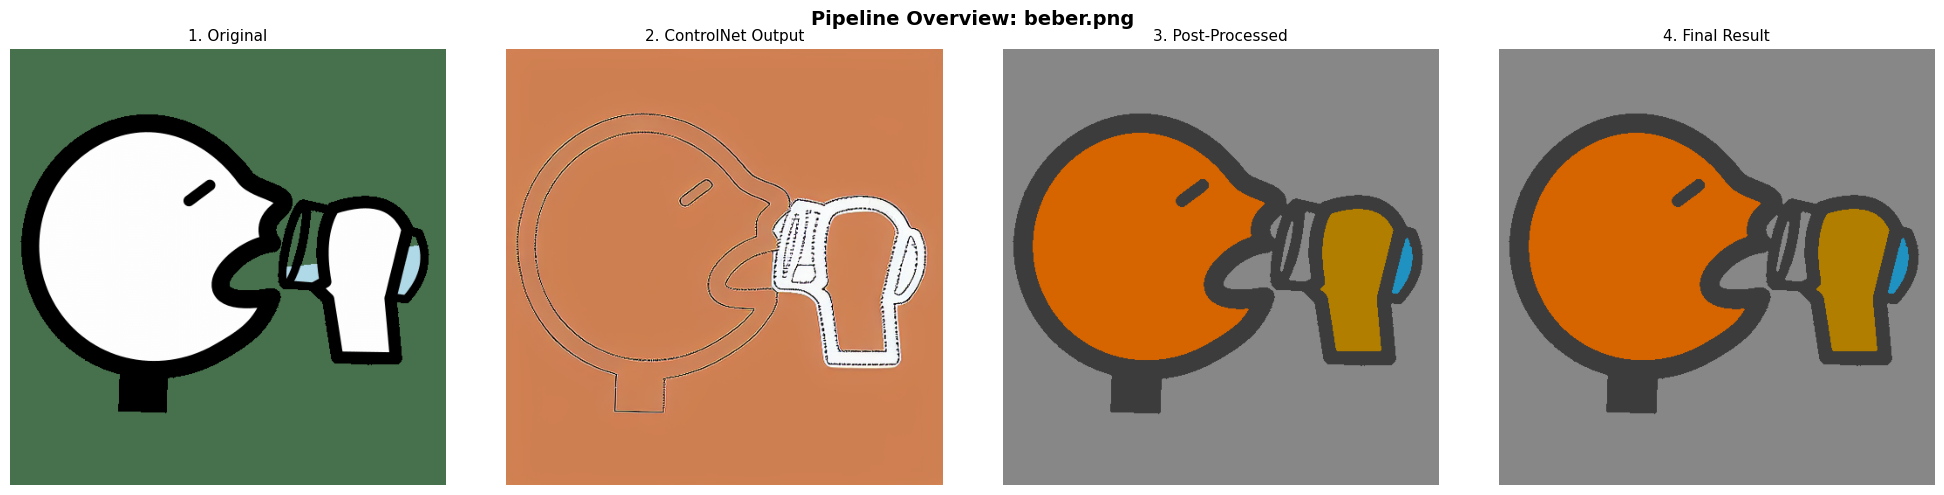

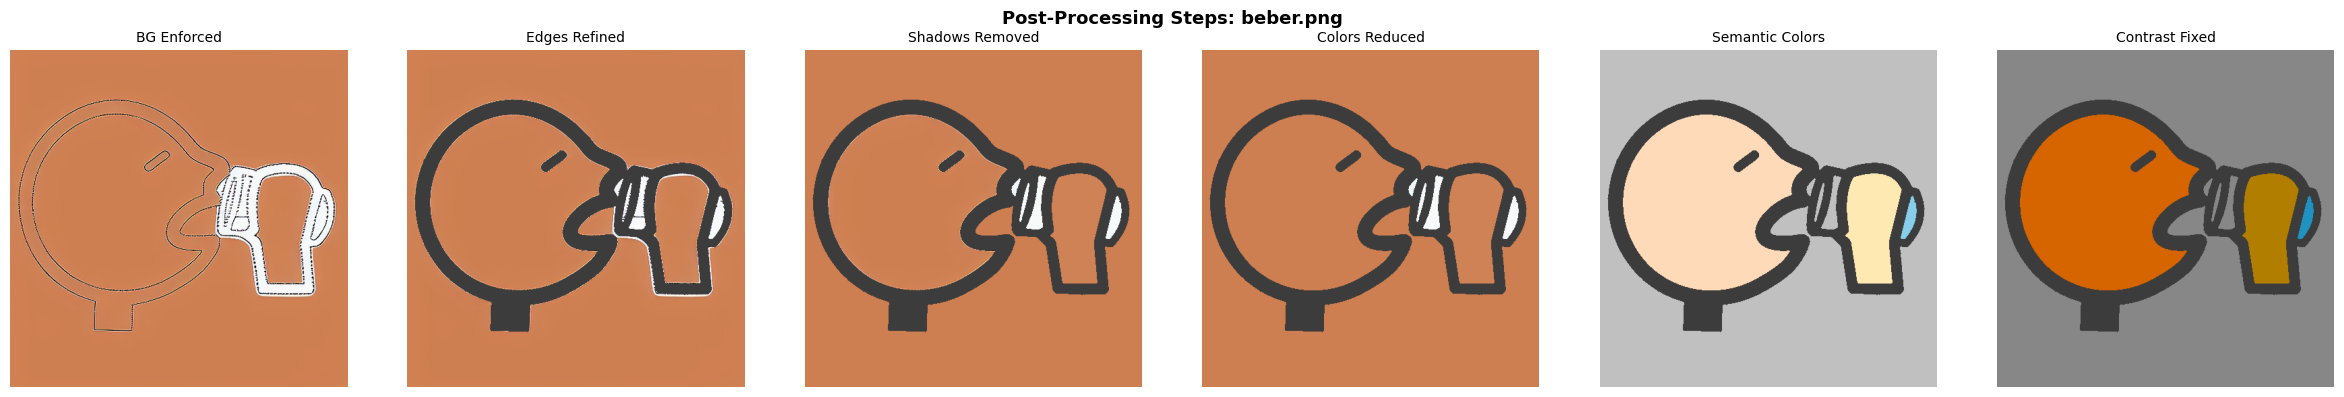

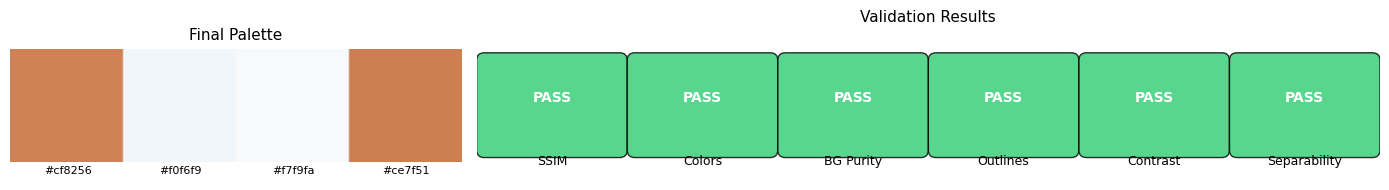


 Processing: comer.png

[Stage 1] Structure: 6 regions
[Stage 2+3] Generation complete (SSIM: 0.868)
[Stage 4] Post-processing...
  Step 4.1: Enforcing background...
  Step 4.3: Refining edges (moved before color ops)...
  Step 4.2: Removing shadows/gradients...
  Step 4.4: Adaptive color reduction...
  Palette: 4 colors
    Color 1: RGB(189, 165, 159) = #bda59f
    Color 2: RGB(186, 119, 76) = #ba774c
    Color 3: RGB(215, 185, 161) = #d7b9a1
    Color 4: RGB(214, 183, 159) = #d6b79f
  Step 4.5: Semantic color assignment (using original colors)...
  Region 1: object -> RGB(192, 192, 192) (#c0c0c0)
  Region 2: skin -> RGB(255, 218, 185) (#ffdab9)
  Region 5: skin -> RGB(255, 233, 178) (#ffe9b2)
  Region 4: food -> RGB(255, 165, 0) (#ffa500)
  Region 3: object -> RGB(192, 192, 192) (#c0c0c0)
  Region 6: skin -> RGB(255, 233, 178) (#ffe9b2)
  Step 4.6: WCAG contrast validation...
  Contrast Validation (minimum ratio: 4.5:1):
    Region 1: vs BG=4.74:1, vs outline=3.07:1 [PASS] (adjusted

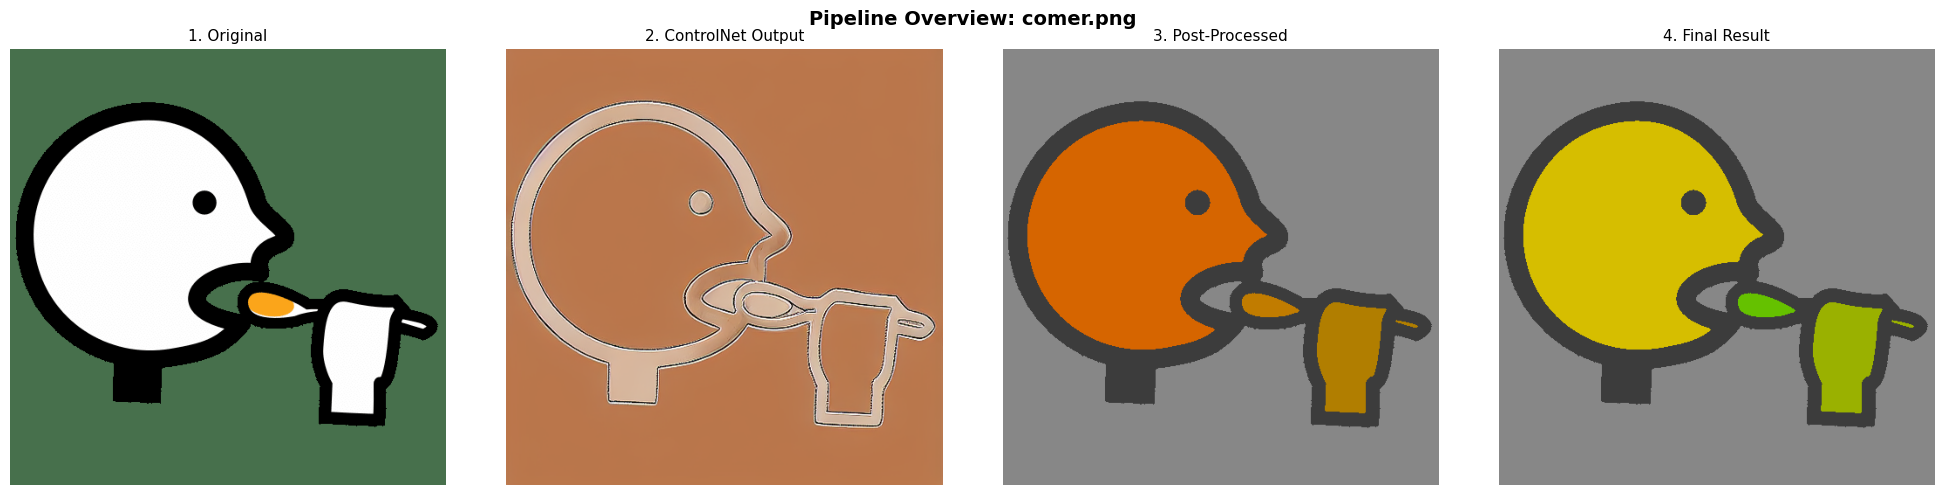

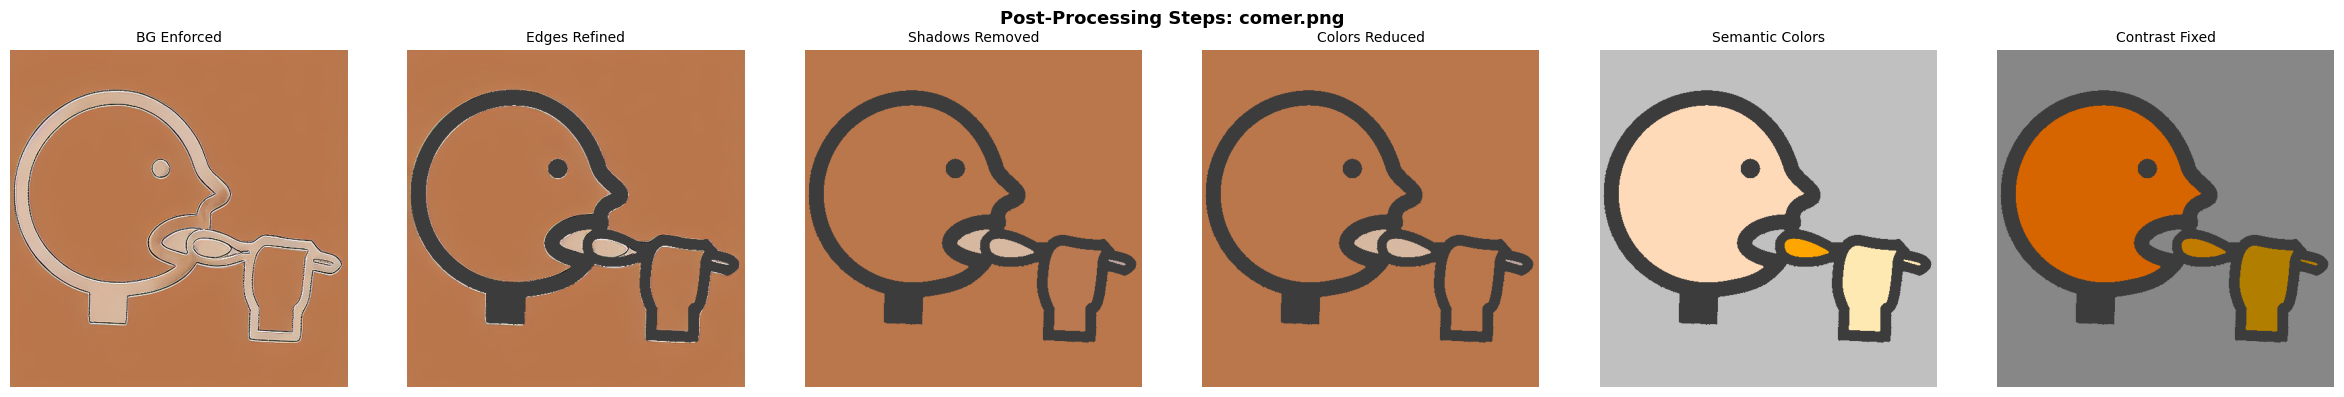

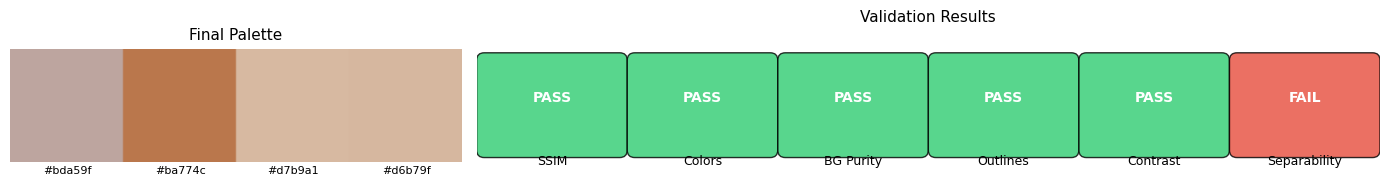


 All 2 pictogram(s) processed.


In [ ]:
# ============================================================
# Cell 32: Execute Full Pipeline
# ============================================================

results = []

for name, img in input_images.items():
    print(f"\n{'='*60}")
    print(f" Processing: {name}")
    print(f"{'='*60}")

    # Stage 1: Structure extraction (already done)
    s = structures[name]
    print(f"\n[Stage 1] Structure: {s['num_regions']} regions")

    # Stage 2+3: ControlNet generation (already done)
    gen_img = generated_images[name]
    gen_score = generation_scores[name]
    print(f"[Stage 2+3] Generation complete (SSIM: {gen_score:.3f})")

    # Stage 4: Clinical post-processing
    # [FIX #6] Pass generation_ssim for fallback logic
    print(f"[Stage 4] Post-processing...")
    final_pil, intermediates, meta = clinical_postprocess(
        gen_img, img, s, sensory_profile,
        generation_ssim=gen_score
    )

    # Stage 5: Validation
    print(f"\n[Stage 5] Validating...")
    validation = validate_output(img, final_pil, s, sensory_profile, meta)

    # If validation fails on semantic separability, attempt re-adjustment
    if not validation.get('semantic_separability', {}).get('pass', True):
        print("\n  ⚠ Semantic separability failed — re-adjusting colors...")
        proc_np = np.array(final_pil)
        labels = meta['labels']
        corrected = meta['corrected_colors']
        semantics = meta['region_semantics']

        cat_offset = {}
        offset_step = 25
        for lid, cat in semantics.items():
            if cat not in cat_offset:
                cat_offset[cat] = len(cat_offset) * offset_step
            if lid in corrected:
                c = corrected[lid]
                h, l, s_val = colorsys.rgb_to_hls(
                    c[0]/255, c[1]/255, c[2]/255
                )
                h = (h + cat_offset[cat]/360) % 1.0
                r, g, b = colorsys.hls_to_rgb(h, l, s_val)
                new_c = (int(r*255), int(g*255), int(b*255))
                mask = (labels == lid)
                if mask.sum() >= 50:
                    proc_np[mask] = new_c

        proc_np, _ = refine_edges(proc_np, s['outline_mask'])
        final_pil = Image.fromarray(proc_np)
        print("  ✓ Colors re-adjusted")

    # Visualization
    print(f"\n[Visualization]")
    visualize_pipeline(name, img, intermediates, final_pil, validation, meta)

    results.append({
        'name': name,
        'final': final_pil,
        'validation': validation,
        'meta': meta
    })

print(f"\n{'='*60}")
print(f" All {len(results)} pictogram(s) processed.")
print(f"{'='*60}")

--- ## 📚 Conclusión y Notas Clínicas ### Lo que hace este 'pipeline' 1. **Preserva la estructura** — el condicionamiento de ControlNet en los bordes de Canny asegura que el pictograma adaptado retenga el diseño espacial del símbolo original. 2. **Aplica propiedades clínicas** — el post-procesamiento determinístico garantiza colores planos, fondos uniformes, paletas controladas y contraste compatible con WCAG. 3. **Mantiene la claridad semántica** — el procesamiento de color por región y la asignación semántica evitan la fusión de objetos. 4. **Valida la salida** — las comprobaciones automatizadas aseguran que el resultado sea estructuralmente fiel y clínicamente utilizable. 5. **Falla de forma segura** — si la salida de ControlNet es demasiado divergente, el 'pipeline' recurre a colorear la imagen original directamente. ### Limitaciones - **Fidelidad de ControlNet**: El modelo generativo puede no seguir perfectamente estructuras de borde complejas. El mecanismo de respaldo lo compensa. - **Clasificación semántica**: El sistema de reglas basado en el tono es heurístico. Los esquemas de color inusuales pueden ser mal clasificados. - **Contexto de imagen única**: Cada pictograma se procesa de forma independiente; la coherencia de la paleta entre pictogramas requiere una coordinación separada. ### Recomendaciones Clínicas - **Siempre haga que un patólogo del habla y lenguaje (SLP) revise** los pictogramas adaptados antes de usarlos con un niño. - **Pruebe con el niño específico** — incluso los pictogramas validados pueden no funcionar para cada individuo. - **Mantenga la coherencia** — use el mismo perfil sensorial en todos los pictogramas del sistema de CAA de un niño. - **Documente las adaptaciones** — registre qué configuraciones de perfil funcionan para cada niño. ### Principio Clave "La claridad semántica y la accesibilidad cognitiva son más importantes que el realismo visual o la estética."

### 3.3.10. Normalización y procesamiento inicial de pictogramas

Para asegurar la consistencia y la adaptabilidad de los pictogramas, el proceso comienza con una fase de normalización y procesamiento inicial. Esta etapa es crucial para preparar las imágenes originales para la generación con Stable Diffusion y ControlNet, extrayendo las características estructurales esenciales y definiendo los parámetros de estilo.

**1. Extracción de la Estructura (función `extract_structure`):**

Esta función es el primer paso para analizar los pictogramas cargados. Su objetivo principal es descomponer la imagen en componentes estructurales clave que guiarán la generación:

*   **Detección de Bordes Canny:** Se aplica un algoritmo de Canny para identificar y resaltar los contornos principales del pictograma. Estos bordes servirán como la condición de entrada para ControlNet, asegurando que la imagen generada mantenga la forma y el esqueleto del original.
*   **Máscara de Contorno:** Se crea una máscara binaria que aísla los trazos oscuros o el delineado principal del pictograma. Esto es útil para re-aplicar bordes limpios en etapas posteriores del procesamiento.
*   **Máscara de Fondo:** Se identifica y aísla el fondo de la imagen, utilizando un proceso de "relleno por inundación" desde los bordes. Esto permite que el fondo sea reemplazado por un color uniforme y controlado.
*   **Componentes Conectados Interiores:** Se identifican las regiones internas del pictograma que están rodeadas por contornos y que serán coloreadas. Esto es fundamental para la cuantificación de color por región.

**Imagen Recomendada:** Incluya la visualización de la **"Structure Extraction"** generada en la **Celda 7** (`ZX_iRLAdF9So`). Esta imagen de 4 paneles (Original, Canny Edges, Outline Mask, Background Mask) ilustra perfectamente los outputs de esta etapa.

**2. Construcción de 'Prompts' (función `build_prompts`):**

Paralelamente a la extracción de la estructura, se generan los `prompts` textuales (positivo y negativo) que guiarán la inferencia de Stable Diffusion. Esta función toma la información del `sensory_profile` definido por el usuario (color de fondo, nivel de contraste, colores prohibidos) y la actividad del pictograma para construir instrucciones detalladas:

*   **Prompt Positivo:** Describe las características deseadas en la imagen generada, como el estilo (ARASAAC, vectorial, 2D, colores planos), la descripción de la actividad, el color de fondo específico, el nivel de contraste, y detalles como "contornos finos, minimalista, apto para niños".
*   **Prompt Negativo:** Especifica lo que se debe evitar, incluyendo bajo contraste, sombras, degradados, texturas, efectos 3D, colores oscuros o prohibidos, y elementos distractores. Esta cuidadosa ingeniería de `prompts` es clave para lograr pictogramas que cumplan con los criterios clínicos.

Estas fases iniciales preparan el terreno para la generación y post-procesamiento, asegurando que la información esencial de la imagen original se capture y que la guía estilística para la IA sea precisa.

### 3.3.12. Pruebas de cumplimiento de la interacción 1

La fase de Pruebas de Cumplimiento es fundamental para verificar que los pictogramas generados no solo son estéticamente adaptados, sino que también cumplen rigurosamente con las especificaciones clínicas y de accesibilidad definidas en el `sensory_profile`. La función `validate_output` (Celda 28 `fTsuKxmiF9S9`) realiza una serie de comprobaciones objetivas:

1.  **Similitud Estructural (SSIM):**
    *   **Propósito:** Evalúa qué tan bien la estructura (bordes) del pictograma adaptado se alinea con la del pictograma original. Un SSIM alto (ej. ≥ 0.70) indica que la forma y los contornos esenciales se han mantenido.
    *   **Método:** Se compara el mapa de bordes Canny del original con el del adaptado. Esta métrica es crucial para asegurar que la representación visual del concepto no se haya distorsionado.

2.  **Conteo de Colores:**
    *   **Propósito:** Verifica que el número de colores distintos en el pictograma final se mantiene dentro de un rango aceptable, en línea con los requisitos de simplicidad visual (ej. `k_colores_max`).
    *   **Método:** Cuenta los colores únicos y lo compara con el máximo esperado, asegurando una paleta controlada.

3.  **Pureza del Fondo:**
    *   **Propósito:** Garantiza que el color de fondo es uniforme y coincide con el `color_fondo_hex` especificado en el perfil sensorial.
    *   **Método:** Analiza los píxeles identificados como fondo en el pictograma final para detectar cualquier desviación significativa del color de fondo objetivo.

4.  **Continuidad de los Contornos:**
    *   **Propósito:** Evalúa si los contornos principales del pictograma se mantienen íntegros y bien definidos en la imagen adaptada.
    *   **Método:** Mide el solapamiento entre los contornos originales y las áreas oscuras del pictograma procesado. Una alta continuidad (ej. ≥ 85%) indica bordes claros y sin interrupciones.

5.  **Cumplimiento del Contraste (WCAG):**
    *   **Propósito:** Es una de las pruebas más críticas. Asegura que la relación de contraste entre cada región de color y el fondo, así como entre cada región y los propios contornos, cumple con los estándares WCAG (Web Content Accessibility Guidelines).
    *   **Método:** Se calculan las relaciones de contraste para cada par de colores adyacentes y se ajustan los colores si no cumplen con el `contraste_minimo` requerido.

6.  **Separabilidad Semántica:**
    *   **Propósito:** Confirma que las regiones semánticamente distintas (ej. piel, comida, líquido, objeto) tienen colores suficientemente diferenciados para evitar confusiones visuales.
    *   **Método:** Analiza las distancias en el espacio de color LAB entre los colores asignados a diferentes categorías semánticas. Una buena separabilidad asegura que cada elemento es claramente perceptible.

Finalmente, se genera un **reporte de validación consolidado** que indica si cada criterio se "PASA" o "FALLA", culminando en un veredicto "OVERALL" de cumplimiento para el pictograma. En caso de fallos en la separabilidad semántica, el sistema intenta un reajuste de colores como medida correctiva.

**Imagen Recomendada:** Incluya la visualización del **"Validation Results"** que se muestra en la **Celda 30** (`LMtEkOG7F9S-`). Esta sección, que usa "badges" o "etiquetas" de PASS/FAIL, es una representación concisa y efectiva de las pruebas de cumplimiento.

In [ ]:
# ============================================================
# Cell 34: Save & Download Results
# ============================================================

output_paths = []
for r in results:
    out_name = f"adapted_{r['name']}"
    r['final'].save(out_name)
    output_paths.append(out_name)
    overall = 'PASS' if r['validation']['overall'] else 'FAIL'
    print(f"Saved: {out_name} (Validation: {overall})")

try:
    from google.colab import files
    for path in output_paths:
        files.download(path)
    print("\nDownload triggered for all adapted pictograms.")
except ImportError:
    print(f"\nSaved locally: {output_paths}")

print("\n Pipeline complete.")

Saved: adapted_beber.png (Validation: PASS)
Saved: adapted_comer.png (Validation: FAIL)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download triggered for all adapted pictograms.

 Pipeline complete.
